# SmokeSignal: should tomorrow's practice be outdoors?

**Veritas AI International High School Hackathon 2026**

**Track:** AI + Climate (built on suggested project 4.3.2, Next-day air quality forecast)
**Team:** Jonathan (solo)

**One-sentence pitch:** SmokeSignal helps a Montgomery County athletic director decide whether tomorrow’s practice should be outdoors, by forecasting tomorrow’s air quality and warning when wildfire smoke is on the way.

**How to run:** Runtime → Run all. The first run downloads about 75 MB of EPA data and takes a few minutes

**Abstract:** My forecast model beat the simple baseline on normal days, but it missed the smoke days, which are the ones that matter. A simple upwind warning caught them.

## 1. Who this is for
In June 2023, smoke from Canadian wildfires made the air around DC unhealthy for several days. Schools had to decide on short notice whether to cancel outdoor sports. My user is an athletic director at a Montgomery County high school. Around 3 PM right when school ends they set tomorrow's practice plan: outdoors as normal, or have an indoor backup ready. I use the line 35.4 µg/m³ for the daily average PM2.5. Above that, the EPA's Air Quality Index goes over 100, which it calls "Unhealthy for Sensitive Groups". That group includes children and people with asthma, and anyone else who might be harmed.

## 2. Load the data
The project brief suggests OpenAQ, but I used the EPA’s AirData files instead. They don’t need an API key, so the notebook runs for anyone, and one file per year covers every monitor I needed in Maryland, Pennsylvania and New York.

- **PM2.5:** the EPA's AirData daily files, one zip per year for 2017–2025. Each file has the daily average from every official monitor in the US.
- **Weather:** Open-Meteo's historical weather API for Rockville (temperature, rain, wind speed, humidity).

The EPA files cover the whole country, so I keep only the mid-Atlantic and build three daily numbers from them

- **Rockville** (monitor 24-031-3001, Montgomery County). This is what I forecast.
- **DC–Baltimore:** the average of the other monitors nearby. I use it to fill in days when the Rockville monitor has no reading.
- **Upwind north:** the average of monitors in Pennsylvania and upstate New York (latitude 40–44°N, longitude 80.5–74.5°W). Smoke from Canada usually passes over these first.

The first run saves the cleaned tables in `data/`, so running it again is fast.

In [ ]:
import os, zipfile, textwrap, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

os.makedirs("data", exist_ok=True)
YEARS = range(2017, 2026)
ROCKVILLE = "24-031-3001"                      # state 24 (MD), county 031 (Montgomery), site 3001
HEADERS = {"User-Agent": "Mozilla/5.0 (student hackathon project)"}
EPA_URL = "https://aqs.epa.gov/aqsweb/airdata/daily_88101_{year}.zip"   # 88101 is the EPA code for PM2.5
EPA_COLS = ["State Code", "County Code", "Site Num", "Latitude", "Longitude",
            "Sample Duration", "Date Local", "Arithmetic Mean"]

def load_epa_year(year):
    # Download one year of EPA data (if we don't have it yet) and keep the part we need
    path = f"data/daily_88101_{year}.zip"
    if not os.path.exists(path):
        r = requests.get(EPA_URL.format(year=year), headers=HEADERS, timeout=300)
        r.raise_for_status()
        open(path, "wb").write(r.content)
    with zipfile.ZipFile(path) as z:
        with z.open(z.namelist()[0]) as f:
            d = pd.read_csv(f, usecols=EPA_COLS,
                            dtype={"State Code": str, "County Code": str, "Site Num": str})
    d = d[d["Sample Duration"] != "1 HOUR"]        # drop hourly-monitor rows, keep the 24-hour averages
    d = d[d["Latitude"].between(37.5, 44) & d["Longitude"].between(-81, -74)]   # mid-Atlantic only
    d["site"] = d["State Code"] + "-" + d["County Code"] + "-" + d["Site Num"]
    # Some sites have more than one instrument, so average them to get one value per site per day
    return (d.groupby(["site", "Date Local"])
             .agg(lat=("Latitude", "first"), lon=("Longitude", "first"), pm=("Arithmetic Mean", "mean"))
             .reset_index().rename(columns={"Date Local": "date"}))

def build_pm_table(s):
    # Turn the long table (one row per site per day) into three daily columns
    local = s[s.site == ROCKVILLE].groupby("date").pm.mean()
    dcbalt = s[(s.site != ROCKVILLE) & s.lat.between(38.6, 39.6) & s.lon.between(-77.7, -76.4)].groupby("date").pm.mean()
    north = s[s.lat.between(40.0, 44.0) & s.lon.between(-80.5, -74.5)].groupby("date").pm.mean()
    out = pd.DataFrame({"pm_rockville": local, "pm_dcbalt": dcbalt, "pm_north": north})
    out.index = pd.to_datetime(out.index)
    return out.rename_axis("date").sort_index().round(1)

if os.path.exists("data/pm25_daily.csv"):          # already built on an earlier run
    pm = pd.read_csv("data/pm25_daily.csv", parse_dates=["date"], index_col="date")
else:
    pm = build_pm_table(pd.concat([load_epa_year(y) for y in YEARS]))
    pm.to_csv("data/pm25_daily.csv")

WX_URL = ("https://archive-api.open-meteo.com/v1/archive?latitude=39.08&longitude=-77.15"
          "&start_date=2017-01-01&end_date=2025-12-31"
          "&daily=temperature_2m_mean,precipitation_sum,wind_speed_10m_mean,relative_humidity_2m_mean"
          "&timezone=America/New_York")
if os.path.exists("data/weather_daily.csv"):
    wx = pd.read_csv("data/weather_daily.csv", parse_dates=["date"], index_col="date")
else:
    j = requests.get(WX_URL, headers=HEADERS, timeout=120).json()["daily"]
    wx = pd.DataFrame({"date": pd.to_datetime(j["time"]), "temp_c": j["temperature_2m_mean"],
                       "precip_mm": j["precipitation_sum"], "wind_kmh": j["wind_speed_10m_mean"],
                       "rh_pct": j["relative_humidity_2m_mean"]}).set_index("date")
    wx.to_csv("data/weather_daily.csv")

df = pm.join(wx, how="outer").asfreq("D")           # one row per calendar day, even if a reading is missing
print(f"{len(df):,} days from {df.index.min().date()} to {df.index.max().date()}")
print(f"Rockville has a reading on {df.pm_rockville.notna().mean():.0%} of days")
df.head()

3,287 days from 2017-01-01 to 2025-12-31
Rockville has a reading on 94% of days


,pm_rockville,pm_dcbalt,pm_north,temp_c,precip_mm,wind_kmh,rh_pct
date,,,,,,,
2017-01-01,6.3,8.7,9.8,5.6,0.0,9.1,64
2017-01-02,5.6,9.5,11.3,5.0,4.0,12.0,90
2017-01-03,0.7,5.8,4.9,5.3,15.8,7.2,98
2017-01-04,0.5,3.7,5.5,6.6,0.3,17.8,67
2017-01-05,3.7,5.3,7.5,-0.9,1.4,9.6,56


## 3. Look at the data first
Before training anything, I wanted to know how often the air in Rockville is actually unhealthy.

Days above 35.4 µg/m³ at Rockville, by year:
date
2017    0
2018    0
2019    0
2020    0
2021    0
2022    0
2023    3
2024    0
2025    0


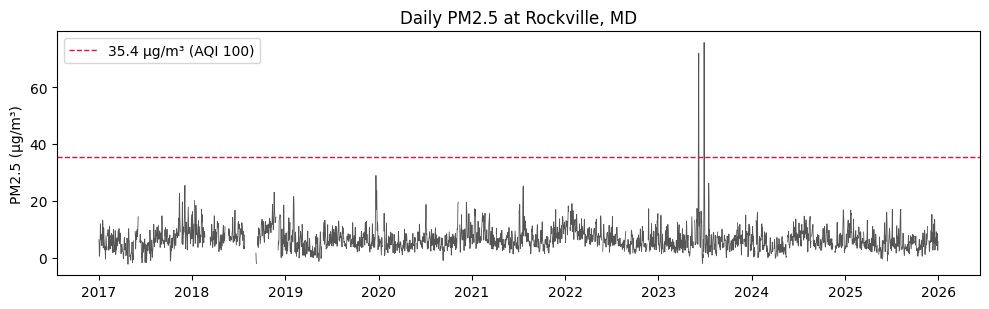

In [ ]:
per_year = (df.pm_rockville > 35.4).groupby(df.index.year).sum()
print("Days above 35.4 µg/m³ at Rockville, by year:")
print(per_year.to_string())

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(df.index, df.pm_rockville, lw=0.6, color="#555")
ax.axhline(35.4, color="crimson", ls="--", lw=1, label="35.4 µg/m³ (AQI 100)")
ax.set_ylabel("PM2.5 (µg/m³)"); ax.set_title("Daily PM2.5 at Rockville, MD"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

I didn't expect this

From 2017 to 2022, Rockville never went above 35.4 once. Then in June 2023 the wildfire smoke pushed it past 70. So a model trained on the earlier years has never seen a day like that. A few readings are slightly below zero; probably noise on clean days. The EPA keeps those values in its files, so I left them in.

Here is June 2023 up close, with the upwind monitors added.


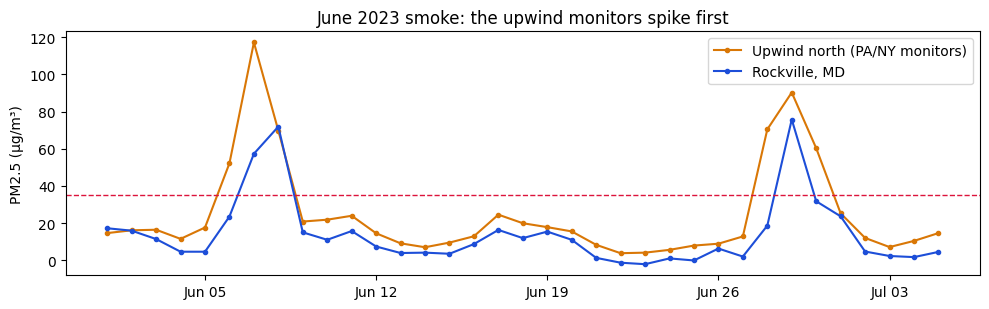

            pm_north  pm_rockville
date                              
2023-06-05      17.7           4.7
2023-06-06      52.2          23.6
2023-06-07     117.1          57.3
2023-06-08      69.7          71.9


In [ ]:
jun = df.loc["2023-06-01":"2023-07-05"]
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(jun.index, jun.pm_north, marker="o", ms=3, label="Upwind north (PA/NY monitors)", color="#d97706")
ax.plot(jun.index, jun.pm_rockville, marker="o", ms=3, label="Rockville, MD", color="#1d4ed8")
ax.axhline(35.4, color="crimson", ls="--", lw=1)
ax.set_ylabel("PM2.5 (µg/m³)"); ax.set_title("June 2023 smoke: the upwind monitors spike first"); ax.legend()
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.tight_layout(); plt.show()
print(jun.loc["2023-06-05":"2023-06-08", ["pm_north", "pm_rockville"]])

On June 6 the upwind monitors were already at 52 µg/m³ while Rockville was at 24. The next day Rockville hit 57. The smoke shows up in Pennsylvania and New York about a day before it gets here. I come back to this in section 8.



## 4. Features, and a fair time split
Each row is one day ("today"), and the thing I want to predict is tomorrow's PM2.5 in Rockville. The inputs are things you would know today:

- today's and yesterday's PM2.5 in Rockville
- today's weather: temperature, rain, wind speed, humidity
- the time of year. I turn the day of the year into a point on a circle using sine and cosine, so that Dec 31 and Jan 1 end up next to each other instead of 365 apart.
- today's PM2.5 at the upwind monitors, and how much dirtier it is there than in Rockville. Only Model 2 gets these two.

I train on 2017–2022 and test on 2023–2025. I don't shuffle the days, because a forecast should always be tested on dates that come after everything it learned from.

In [ ]:
d = df.copy()
d["pm_today"] = d.pm_rockville.fillna(d.pm_dcbalt)          # if Rockville is missing, use the nearby average
d["pm_yday"] = d.pm_today.shift(1)                          # shift(1) moves the column down a row = yesterday
d["target"] = d.pm_rockville.shift(-1)                      # shift(-1) moves it up a row = tomorrow's real reading
d["pm_north_today"] = d.pm_north
d["north_minus_local"] = d.pm_north - d.pm_today            # the "upwind gap"
d["doy_sin"] = np.sin(2 * np.pi * d.index.dayofyear / 365.25)
d["doy_cos"] = np.cos(2 * np.pi * d.index.dayofyear / 365.25)

d = d.dropna(subset=["target", "pm_today"])                 # can't train or score a day with no answer
train, test = d[d.index < "2023-01-01"], d[d.index >= "2023-01-01"]
y_train, y_test = train.target, test.target
print(f"Train: {len(train):,} days (2017–2022), {int((y_train > 35.4).sum())} unhealthy days")
print(f"Test:  {len(test):,} days (2023–2025), {int((y_test > 35.4).sum())} unhealthy days")

Train: 2,034 days (2017–2022), 0 unhealthy days
Test:  1,046 days (2023–2025), 3 unhealthy days


I score the forecasts with **mean absolute error** (MAE): on average, how many µg/m³ the forecast is off by. Lower is better. If $y_i$ is the real value on test day $i$, $\hat{y}_i$ is the forecast for that day, and $n$ is the number of test days:

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n} \left|\, y_i - \hat{y}_i \,\right|$$

## 5. Baseline: tomorrow will be the same as today
This is the persistence baseline from the brief. Any model has to beat it.

In [ ]:
def mae(pred):
    return mean_absolute_error(y_test, pred)

results = {}
results["Baseline: tomorrow = today"] = mae(test.pm_today)
print(f"Baseline MAE: {results['Baseline: tomorrow = today']:.2f} µg/m³")

Baseline MAE: 2.43 µg/m³


## 6. Two models
**Model 1** is linear regression on today's PM2.5, the weather and the time of year. It learns one weight for each input and adds them up.
**Model 2** is gradient-boosted decision trees (`HistGradientBoostingRegressor` in scikit-learn), and it also gets the two upwind inputs. A decision tree is like a flowchart of yes/no questions ("is today's PM2.5 above 12?") that ends in a number. Boosting builds a few hundred small trees one after another, and each new tree tries to fix the mistakes left by the ones before it.

In [ ]:
BASE = ["pm_today", "pm_yday", "temp_c", "precip_mm", "wind_kmh", "rh_pct", "doy_sin", "doy_cos"]
UPWIND = BASE + ["pm_north_today", "north_minus_local"]
fill = train[UPWIND].median()        # a few inputs are missing; fill them with the typical training value

# scikit-learn models all work the same way: .fit(inputs, answers) to learn, .predict(inputs) to forecast
m1 = LinearRegression().fit(train[BASE].fillna(fill), y_train)
pred1 = pd.Series(m1.predict(test[BASE].fillna(fill)), index=test.index)
results["Model 1: linear regression"] = mae(pred1)

# 300 small trees, each one making a small (0.05) correction. I did not tune these two settings.
m2 = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=0)
m2.fit(train[UPWIND].fillna(fill), y_train)
pred2 = pd.Series(m2.predict(test[UPWIND].fillna(fill)), index=test.index)
results["Model 2: boosted trees + upwind"] = mae(pred2)

base_mae = results["Baseline: tomorrow = today"]
for name, v in results.items():
    print(f"{name:34s} MAE {v:.2f}   ({1 - v / base_mae:.0%} better than baseline)")

Baseline: tomorrow = today         MAE 2.43   (0% better than baseline)
Model 1: linear regression         MAE 2.14   (12% better than baseline)
Model 2: boosted trees + upwind    MAE 2.12   (13% better than baseline)


Both models beat the baseline by about 12–13%, which is around 0.3 µg/m³. That's a small gain, so "tomorrow equals today" turned out to be hard to beat. Model 2 is only a tiny bit better than Model 1.

## 7. Where the models fail
An average error of about 2 µg/m³ sounds good. But the athletic director doesn't need help on ordinary days. They need it on the few days when the air is dangerous. These are all the test days where tomorrow turned out unhealthy:

In [ ]:
unhealthy = y_test > 35.4        # True on the test days where tomorrow really was above 35.4
show = pd.DataFrame({"today (Rockville)": test.pm_today, "upwind north today": test.pm_north_today,
                     "Model 1 forecast": pred1.round(1), "Model 2 forecast": pred2.round(1),
                     "actual tomorrow": y_test})[unhealthy]
print(show.to_string())
print(f"\nTraining days above 35.4: {int((y_train > 35.4).sum())}.  Highest value in training: {y_train.max():.1f} µg/m³")

            today (Rockville)  upwind north today  Model 1 forecast  Model 2 forecast  actual tomorrow
date                                                                                                  
2023-06-06               23.6                52.2              18.3              19.0             57.3
2023-06-07               57.3               117.1              40.3              18.5             71.9
2023-06-28               18.7                70.4              14.2              16.3             75.7

Training days above 35.4: 0.  Highest value in training: 28.9 µg/m³


This is the most important result in the notebook. The first and third rows are the days right before the smoke arrived, and both models forecast an ordinary day. Model 2 never gets close to 35.4. Model 1 only goes above it in the middle row, when Rockville was already at 57, so that's not an early warning.
I think there are two reasons. First, the training years have no days above 35.4 at all (the highest is 28.9). A tree model's forecast is built from the training days it has seen, so it can't go much higher than they did. Second, in 2017–2022 dirty air upwind was never followed by an unhealthy day here, so nothing taught the models to pay attention to it.

To check the second reason, I gave the linear model the upwind reading too:

In [ ]:
m1_up = LinearRegression().fit(train[BASE + ["pm_north_today"]].fillna(fill), y_train)
pred1_up = pd.Series(m1_up.predict(test[BASE + ["pm_north_today"]].fillna(fill)), index=test.index)
print(f"Linear regression with the upwind reading added: MAE {mae(pred1_up):.2f}")
print("  its forecasts for the three unhealthy days:", pred1_up[unhealthy].round(1).tolist())
print(f"  the weight it learned for the upwind reading: {m1_up.coef_[-1]:.2f}")

Linear regression with the upwind reading added: MAE 2.14
  its forecasts for the three unhealthy days: [18.4, 40.6, 14.4]
  the weight it learned for the upwind reading: 0.00


The weight it learned for the upwind reading is basically zero, and its forecasts for the three days hardly change. So this isn't only a tree problem. The training years just didn't contain the pattern.

## 8. My addition: an upwind smoke watch

Since the models couldn't learn the pattern, I added it as one simple rule on top of Model 2:

> **Smoke watch:** warn if the upwind monitors are more than **T** µg/m³ dirtier than Rockville today.

T comes from the training years only. I took the gap (upwind minus Rockville) for every day in 2017–2022 and set T at the 99.5th percentile, which means the gap was bigger than T on only about 1 training day in 200. The final call is "plan indoors" if Model 2 forecasts above 35.4 or the smoke watch fires.

In [ ]:
T = round(train.north_minus_local.quantile(0.995), 1)
print(f"T from the training years: {T} µg/m³")
print(f"In the training years the smoke watch would have fired on {int((train.north_minus_local > T).sum())} days (none were followed by an unhealthy day, because there weren't any).\n")

smoke_watch = test.north_minus_local > T
alerts = {
    "Baseline: warn if today > 35.4": test.pm_today > 35.4,
    "Model 1 alone": pred1 > 35.4,
    "Model 2 alone": pred2 > 35.4,
    "SmokeSignal: Model 2 OR smoke watch": (pred2 > 35.4) | smoke_watch,
}
n_years = (test.index.max() - test.index.min()).days / 365.25
rows = []
for name, a in alerts.items():
    rows.append({"method": name,
                 "unhealthy days caught": f"{int((a & unhealthy).sum())} / {int(unhealthy.sum())}",
                 "extra warnings": int((a & ~unhealthy).sum()),          # warned, but tomorrow was fine
                 "extra warnings per year": round((a & ~unhealthy).sum() / n_years, 1)})
alert_table = pd.DataFrame(rows).set_index("method")
alert_table

T from the training years: 9.8 µg/m³
In the training years the smoke watch would have fired on 10 days (none were followed by an unhealthy day, because there weren't any).



,unhealthy days caught,extra warnings,extra warnings per year
method,,,
Baseline: warn if today > 35.4,1 / 3,2,0.7
Model 1 alone,1 / 3,2,0.7
Model 2 alone,0 / 3,0,0.0
SmokeSignal: Model 2 OR smoke watch,3 / 3,15,5.0


In [ ]:
final = alerts["SmokeSignal: Model 2 OR smoke watch"]
extra = test[final & ~unhealthy]
print(f"Of the {len(extra)} extra warnings, {int((extra.target > 9.0).sum())} were followed by a 'Moderate' day (above 9.0 µg/m³).")
print(f"The worst air after an extra warning was {extra.target.max():.1f} µg/m³.\n")
print(extra[["pm_today", "pm_north_today", "target"]]
      .rename(columns={"pm_today": "Rockville today", "pm_north_today": "upwind today", "target": "Rockville tomorrow"})
      .to_string())

Of the 15 extra warnings, 11 were followed by a 'Moderate' day (above 9.0 µg/m³).
The worst air after an extra warning was 31.8 µg/m³.

            Rockville today  upwind today  Rockville tomorrow
date                                                         
2023-06-05              4.7          17.7                23.6
2023-06-10             11.1          21.9                15.8
2023-06-27              2.1          12.9                18.7
2023-06-29             75.7          90.2                31.8
2023-06-30             31.8          60.3                23.7
2023-07-05              4.6          14.7                 4.6
2023-07-17             26.2          36.2                20.9
2023-07-19              7.7          20.5                 9.8
2025-06-07              2.1          22.0                 7.6
2025-06-08              7.6          20.5                 6.3
2025-08-03              4.7          14.8                10.2
2025-08-04             10.2          23.4                1

SmokeSignal caught all 3 unhealthy days. The baseline and Model 1 each caught 1, and only after the smoke was already here. Model 2 alone caught none. The cost is about 5 extra "have a backup ready" days a year. Five of the eight in 2023 are within a few days of the two June smoke episodes. The August 2025 ones line up with another round of Canadian wildfire smoke, when there were air quality alerts in New York and Pennsylvania. Rockville only reached "Moderate" that time, so the backup plan wouldn't have been needed. For a decision about kids' lungs I think that's an acceptable trade, but it is a real cost.

How much does the choice of percentile matter? Here is the smoke watch on its own with T set at three different percentiles of the training gap:

In [ ]:
rows = []
for pct in [99, 99.5, 99.9]:
    t = round(train.north_minus_local.quantile(pct / 100), 1)
    fires = test.north_minus_local > t
    rows.append({"percentile of training gap": pct, "T (µg/m³)": t,
                 "unhealthy days caught": f"{int((fires & unhealthy).sum())} / {int(unhealthy.sum())}",
                 "extra warnings": int((fires & ~unhealthy).sum())})
pd.DataFrame(rows).set_index("percentile of training gap")

,T (µg/m³),unhealthy days caught,extra warnings
percentile of training gap,,,
99.0,8.4,3 / 3,21
99.5,9.8,3 / 3,15
99.9,11.2,3 / 3,10


All three catch the 3 unhealthy days, and a stricter T gives fewer extra warnings.

This test isn't perfectly fair, though. T is calculated from the training years, but the idea for the rule came from looking at June 2023, which is in the test years. I also tried both the 99th and 99.5th percentiles and kept 99.5 because it gave fewer extra warnings. I checked 99.9 later and decided not to switch, because choosing whatever looks best on the test years would be tuning on the test data. Also, 3 unhealthy days from one smoke season is a very small sample. The real test will be the next smoke season.

## 9. Demo: the 3 PM check

The athletic director types in today's numbers (from AirNow and any weather app) and gets a call and the reason for it. The three examples below are real days from the test years.

In [ ]:
def aqi_category(pm):
    # EPA's 2024 categories for daily PM2.5
    if pm <= 9.0:  return "Good"
    if pm <= 35.4: return "Moderate"
    if pm <= 55.4: return "Unhealthy for Sensitive Groups"
    return "Unhealthy"

def practice_check(pm_rockville_today, pm_upwind_today, temp_c, rain_mm, wind_kmh, humidity_pct,
                   date, pm_rockville_yesterday=None):
    if pm_rockville_yesterday is None:
        pm_rockville_yesterday = pm_rockville_today
    doy = pd.Timestamp(date).dayofyear
    gap = pm_upwind_today - pm_rockville_today
    # Build one row with the same columns, in the same order, that Model 2 was trained on
    x = pd.DataFrame([{"pm_today": pm_rockville_today, "pm_yday": pm_rockville_yesterday,
                       "temp_c": temp_c, "precip_mm": rain_mm, "wind_kmh": wind_kmh, "rh_pct": humidity_pct,
                       "doy_sin": np.sin(2 * np.pi * doy / 365.25), "doy_cos": np.cos(2 * np.pi * doy / 365.25),
                       "pm_north_today": pm_upwind_today, "north_minus_local": gap}])[UPWIND]
    forecast = float(m2.predict(x)[0])

    reasons = []
    if gap > T:
        reasons.append(f"the upwind monitors in PA/NY are {gap:.0f} µg/m³ dirtier than Rockville today, "
                       "which is what it looks like when smoke is on the way")
    if forecast > 35.4:
        reasons.append(f"the model forecasts {forecast:.0f} µg/m³ for tomorrow")
    if reasons:
        msg = (f"PLAN INDOORS. Why: {' and '.join(reasons)}. "
               f"(The model on its own forecasts {forecast:.0f} µg/m³, {aqi_category(forecast)}.) "
               "Have the gym ready as a backup and check AirNow again before practice.")
    else:
        msg = f"Outdoor practice OK. Forecast for tomorrow: {forecast:.0f} µg/m³ ({aqi_category(forecast)}). No smoke building upwind."
    return textwrap.fill(msg, width=100)

for day in ["2023-06-06", "2023-06-28", "2024-04-17"]:
    r = test.loc[day]
    print(f"{day}   (what really happened the next day: {r.target:.0f} µg/m³)")
    print(practice_check(r.pm_today, r.pm_north_today, r.temp_c, r.precip_mm, r.wind_kmh, r.rh_pct, day, r.pm_yday))
    print()

2023-06-06   (what really happened the next day: 57 µg/m³)
PLAN INDOORS. Why: the upwind monitors in PA/NY are 29 µg/m³ dirtier than Rockville today, which is
what it looks like when smoke is on the way. (The model on its own forecasts 19 µg/m³, Moderate.)
Have the gym ready as a backup and check AirNow again before practice.

2023-06-28   (what really happened the next day: 76 µg/m³)
PLAN INDOORS. Why: the upwind monitors in PA/NY are 52 µg/m³ dirtier than Rockville today, which is
what it looks like when smoke is on the way. (The model on its own forecasts 16 µg/m³, Moderate.)
Have the gym ready as a backup and check AirNow again before practice.

2024-04-17   (what really happened the next day: 6 µg/m³)
Outdoor practice OK. Forecast for tomorrow: 5 µg/m³ (Good). No smoke building upwind.



**Optional web app.** Set `RUN_APP = True` to open a simple Gradio page with input boxes and a button. It's off by default so "Run all" finishes quickly.

In [ ]:
RUN_APP = False
if RUN_APP:
    !pip install -q gradio
    import gradio as gr, datetime
    def app(pm_here, pm_up, temp, rain, wind, rh):
        return practice_check(pm_here, pm_up, temp, rain, wind, rh, datetime.date.today())
    gr.Interface(fn=app,
                 inputs=[gr.Number(label="Rockville PM2.5 today (µg/m³)", value=8),
                         gr.Number(label="Upwind PA/NY PM2.5 today (µg/m³)", value=9),
                         gr.Number(label="Temperature (°C)", value=20), gr.Number(label="Rain (mm)", value=0),
                         gr.Number(label="Wind speed (km/h)", value=10), gr.Number(label="Humidity (%)", value=60)],
                 outputs=gr.Textbox(label="SmokeSignal says"), title="SmokeSignal: 3 PM practice check").launch()

## 10. Results summary

In [ ]:
print(pd.DataFrame({"MAE on all test days (µg/m³)": pd.Series(results).round(2)}).to_string(), "\n")
print(alert_table.to_string())

                                 MAE on all test days (µg/m³)
Baseline: tomorrow = today                               2.43
Model 1: linear regression                               2.14
Model 2: boosted trees + upwind                          2.12 

                                    unhealthy days caught  extra warnings  extra warnings per year
method                                                                                            
Baseline: warn if today > 35.4                      1 / 3               2                      0.7
Model 1 alone                                       1 / 3               2                      0.7
Model 2 alone                                       0 / 3               0                      0.0
SmokeSignal: Model 2 OR smoke watch                 3 / 3              15                      5.0


## 11. Limitations and next steps
- The test years have only 3 unhealthy days, all from the June 2023 smoke. Next I'd run the same rule for other cities that got that smoke, like Philadelphia and New York, to see if it holds up on more events.
- I got the idea for the smoke watch from June 2023 and then tested it on June 2023. The threshold comes from earlier years, but the fair test is a smoke season that hasn't happened yet.
- I use the full-day average for "today", but at 3 PM the day isn't over. A real version would use AirNow's hourly readings up to 3 PM.
- My upwind box only looks north. That fits smoke from Canada, but smoke coming from another direction could be missed. A better version would pick the upwind monitors using the wind forecast.
- This is built around one monitor in Rockville, and I haven't shown it to an actual athletic director. I'd want to ask one whether about five extra warnings a year is something they'd put up with.

## Sources
- EPA AirData daily PM2.5 files (parameter 88101, 2017–2025): https://aqs.epa.gov/aqsweb/airdata/download_files.html
- Open-Meteo Historical Weather API: https://open-meteo.com/en/docs/historical-weather-api
- EPA fact sheet on the 2024 AQI breakpoints for PM2.5: https://www.epa.gov/system/files/documents/2024-02/pm-naaqs-air-quality-index-fact-sheet.pdf
- News report on the August 2025 smoke alerts: https://www.scrippsnews.com/science-and-tech/pollution/canadian-wildfire-smoke-is-affecting-air-quality-in-the-midwest-and-northeast-us
- Libraries: pandas, NumPy, scikit-learn, Matplotlib, requests, Gradio (optional)
- AI tools: I used Claude (Opus 5.5 and Fable 5.2). I picked the project idea, fed in my ideas and datasets, while Claude wrote most of the code and did the debugging. I ran everything myself and checked the outputs to ensure consistency. I wrote the explanations and write ups.